# Comparing Three Language Models on Tiny Shakespeare

**Course:** AAI 6620 Applied NLP, Fall 2026
**Author:** Wei Dong
**Task:** Character-level next-token prediction

In this notebook I train a bigram model, an LSTM, and a small Transformer on the same dataset and compare how well each one learns to predict the next character. All three models share the same data split, context length, batch size, and number of training steps so the comparison stays fair.

## 1. Setup

Imports, a fixed random seed, and the shared settings. Every model uses the same batch size, context length, training steps, and evaluation schedule. The learning rate is the one thing I set separately for each model, since different architectures tend to work best with different values.

In [1]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

2.11.0+cu130
True
Tesla T4


In [2]:
import time
import torch
import torch.nn as nn
from torch.nn import functional as F

torch.manual_seed(1337)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Shared settings used by all three models
batch_size = 64       # number of sequences per training step
block_size = 128      # context length (how many characters the model can see)
max_iters = 5000      # training steps
eval_interval = 500   # how often to evaluate
eval_iters = 200      # batches used to estimate loss

## 2. Dataset

I'm using Tiny Shakespeare, a collection of Shakespeare's plays with about 1.1 million characters, taken from Andrej Karpathy's char-rnn repository. It's small enough to train on quickly, but it still has real structure to learn: character names, dialogue, line breaks, and old-fashioned English.

In [3]:
!wget -q https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

print("Total characters:", len(text))
print(text[:500])

Total characters: 1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


## 3. Character Vocabulary

The models work at the character level, so each unique character is one token. The vocabulary has 65 characters, including the newline, space, punctuation, and upper and lower case letters. `encode` turns text into integer IDs, and `decode` turns IDs back into text.

In [4]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print("Vocabulary:", ''.join(chars))
print("Vocab size:", vocab_size)

stoi = {ch: i for i, ch in enumerate(chars)}   # character -> index
itos = {i: ch for i, ch in enumerate(chars)}   # index -> character
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join(itos[i] for i in l)

print(encode("hello"))
print(decode(encode("hello")))

Vocabulary: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
Vocab size: 65
[46, 43, 50, 50, 53]
hello


## 4. Train/Validation Split and Batching

The first 90% of the text is used for training and the last 10% for validation. The models never see the validation text during training, so validation loss tells us whether a model actually picked up patterns in the language or just memorized the training data.

`get_batch` grabs random chunks of 128 characters. The target `y` is the same chunk shifted one character to the right, so at every position the model's job is to guess the next character. You can see this in the output below, where the target is basically the input slid over by one.

In [5]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]
print("Train size:", len(train_data), "| Val size:", len(val_data))

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch('train')
print("x shape:", xb.shape, "| y shape:", yb.shape)
print("Input :", repr(decode(xb[0][:40].tolist())))
print("Target:", repr(decode(yb[0][:40].tolist())))

Train size: 1003854 | Val size: 111540
x shape: torch.Size([64, 128]) | y shape: torch.Size([64, 128])
Input : " guess who caused your father's death.\n\n"
Target: "guess who caused your father's death.\n\nB"


## 5. Shared Training and Evaluation Tools

These functions are used by all three models, which keeps the comparison fair. Every model follows the same interface: it takes a batch of character IDs and returns logits for the next character at each position, plus the cross-entropy loss when targets are given.

`estimate_loss` averages the loss over many random batches so the numbers aren't thrown off by one lucky or unlucky batch. `train_model` runs the same optimizer, number of steps, and evaluation schedule for every model, and it times only the actual training steps, so evaluation doesn't get counted as training time. `generate` samples new text one character at a time, feeding each prediction back in as input.

In [6]:
@torch.no_grad()
def estimate_loss(model):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


results = {}  # stores the final numbers for every model

def train_model(model, name, learning_rate):
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{name}: {n_params:,} parameters")

    history = {'step': [], 'train': [], 'val': []}
    train_time = 0.0

    for it in range(max_iters + 1):
        # evaluate (not counted as training time)
        if it % eval_interval == 0:
            losses = estimate_loss(model)
            history['step'].append(it)
            history['train'].append(losses['train'])
            history['val'].append(losses['val'])
            print(f"step {it:5d} | train loss {losses['train']:.4f} | val loss {losses['val']:.4f}")
        if it == max_iters:
            break

        # one training step (timed)
        t0 = time.time()
        xb, yb = get_batch('train')
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if device == 'cuda':
            torch.cuda.synchronize()
        train_time += time.time() - t0

    print(f"Training time: {train_time:.1f} seconds")
    results[name] = {
        'params': n_params,
        'train_loss': history['train'][-1],
        'val_loss': history['val'][-1],
        'train_time': train_time,
        'history': history,
    }
    return model

In [7]:
@torch.no_grad()
def generate(model, max_new_tokens=500, start_text="\n", seed=42):
    torch.manual_seed(seed)  # same seed for every model, so samples are comparable
    model.eval()
    idx = torch.tensor([encode(start_text)], dtype=torch.long, device=device)
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]          # keep only the last block_size characters
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :]                # prediction for the next character
        probs = F.softmax(logits, dim=-1)
        idx_next = torch.multinomial(probs, num_samples=1)
        idx = torch.cat((idx, idx_next), dim=1)
    model.train()
    return decode(idx[0].tolist())

## 6. Model 1: Bigram

The bigram model predicts the next character using only the current character. Under the hood it's just a 65 × 65 lookup table: row *i* holds the scores (logits) for which character tends to come after character *i*. Training simply tunes that table so it matches how often each pair of characters shows up in the text.

**What it uses:** the single character right before the one it's predicting.

**What it ignores:** everything else. Even though each training chunk is 128 characters long, the bigram model throws away all but the last character at every position. It has no idea what word it's in, who is speaking, or what was said a line ago.

**Why it's limited:** lots of language depends on more than one character of context. After the letter "t", the next character could be "h", "e", a space, or many others, and the only way to narrow it down is to look further back. A bigram model can learn that "q" is almost always followed by "u", but it can't spell longer words or keep a sentence together.

In [8]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        # each character directly looks up the logits for the next character
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)   # (B, T, vocab_size)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

In [9]:
bigram_model = BigramLanguageModel(vocab_size)
bigram_model = train_model(bigram_model, 'Bigram', learning_rate=1e-2)

Bigram: 4,225 parameters
step     0 | train loss 4.7509 | val loss 4.7560
step   500 | train loss 2.5188 | val loss 2.5434
step  1000 | train loss 2.4734 | val loss 2.4984
step  1500 | train loss 2.4639 | val loss 2.4907
step  2000 | train loss 2.4588 | val loss 2.4895
step  2500 | train loss 2.4573 | val loss 2.4857
step  3000 | train loss 2.4559 | val loss 2.4833
step  3500 | train loss 2.4558 | val loss 2.4828
step  4000 | train loss 2.4554 | val loss 2.4820
step  4500 | train loss 2.4543 | val loss 2.4843
step  5000 | train loss 2.4549 | val loss 2.4838
Training time: 15.2 seconds


In [10]:
samples = {}  # stores generated text for every model
samples['Bigram'] = generate(bigram_model, max_new_tokens=500)
print(samples['Bigram'])


I
O: asafite tis, te othut mod thand he, preckn,

Henthim, achishelapinisers we s, orean,
TAUCluprt, ody inde Miced tlat mang yofowhas

Thind.
UCESer url hathapr me machan fl haisu d iere--sthurore cense wn ce me, wouss t avest t, metha'el me herng INGS:

D:BRGLONGof ind s heve she, ENVI an ndowe:
LUSio be's lore we, ba ph, RD foue t he ososour talunghimybr g y stckis thtin;
Bee s mire akns t
Thanesa amnfod bs as Yow:
K:
Tharease V: on my feristhatessotrilorule, maripakn 'sealanks, g duthintide.


### Bigram Results

The loss starts at about 4.75, which is actually higher than random guessing (ln 65 ≈ 4.17), because the embedding table starts out with random values and the model is confidently wrong at first. It drops fast and flattens out around step 2000, ending at 2.455 train and 2.484 val. With only 4,225 parameters (65 × 65), that's pretty much the ceiling for this model. Training longer won't help, because one character of context just doesn't carry more information. The train and val losses are very close, so there's no overfitting; the model is too simple to memorize anything.

The generated text picks up some surface patterns from the play format. Capitalized words followed by a colon show up a lot, which is the model copying speaker labels like "KING:". It also produces line breaks and a few real short words such as "me", "my", and "he". Beyond that it's mostly gibberish. Longer words fall apart because the model can't remember which word it's in the middle of.

## 7. Model 2: LSTM

The LSTM (Long Short-Term Memory) network reads the text one character at a time, left to right, and carries a hidden state along the way. You can think of the hidden state as a running summary of everything the model has read so far in the chunk. At each position, the prediction for the next character comes from that summary, not just from the current character.

**How it uses more context than the bigram:** the bigram model only sees the current character, while the LSTM's prediction at position *t* depends on all the characters from the start of the chunk up to *t*. That lets it keep track of which word it's spelling, whether it's inside a speaker label, and roughly what's going on in the current line.

**What improvement it provides:** it should learn real words, sensible spacing, and basic sentence structure, so the loss should drop well below the bigram's 2.48.

**Why it may still struggle with longer dependencies:** everything the LSTM knows about the past has to be squeezed into one fixed-size hidden vector. As the text gets longer, older information gets overwritten or fades out. The gates in an LSTM help a lot compared with a plain RNN, but they don't fully solve this. The model also has to process characters in order, one after another, so it can't look back directly at a specific earlier character when it needs it. On top of that, the sequential processing makes it hard to parallelize across positions.

My setup uses a 2-layer LSTM with 128-dimensional character embeddings and a 256-dimensional hidden state, which comes out to roughly the same parameter count as the Transformer later on.

In [11]:
n_embd = 128      # embedding size (shared with the Transformer)
dropout = 0.2     # dropout rate (shared with the Transformer)

class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, n_embd, hidden_size=256, num_layers=2, dropout=0.2):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.lstm = nn.LSTM(n_embd, hidden_size, num_layers=num_layers,
                            batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.lm_head = nn.Linear(hidden_size, vocab_size)

    def forward(self, idx, targets=None):
        x = self.token_embedding(idx)          # (B, T, n_embd)
        out, _ = self.lstm(x)                  # (B, T, hidden_size), one output per position
        logits = self.lm_head(self.dropout(out))  # (B, T, vocab_size)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

In [12]:
lstm_model = LSTMLanguageModel(vocab_size, n_embd, hidden_size=256, num_layers=2, dropout=dropout)
lstm_model = train_model(lstm_model, 'LSTM', learning_rate=1e-3)

LSTM: 946,625 parameters
step     0 | train loss 4.1580 | val loss 4.1583
step   500 | train loss 1.6167 | val loss 1.7602
step  1000 | train loss 1.4416 | val loss 1.6181
step  1500 | train loss 1.3596 | val loss 1.5527
step  2000 | train loss 1.3088 | val loss 1.5147
step  2500 | train loss 1.2760 | val loss 1.5037
step  3000 | train loss 1.2457 | val loss 1.4957
step  3500 | train loss 1.2225 | val loss 1.4954
step  4000 | train loss 1.2016 | val loss 1.4819
step  4500 | train loss 1.1821 | val loss 1.4902
step  5000 | train loss 1.1669 | val loss 1.4827
Training time: 126.9 seconds


In [13]:
samples['LSTM'] = generate(lstm_model, max_new_tokens=500)
print(samples['LSTM'])


Is that fair pity see-theart distands,
Septentation will go along and will.
I doubt that, stay upon contrive in your lady
And young princely ament to us, hath promised,
My flowers he is never unor ice, and make:
Have she meet to thee?

PRINCE EDWARD:
See last one of my husband, she, being not a
presence at the man, and speak perfuce; he hath loved
under fortune and the great Beekship's office
To 'we not for his speech, so Duke of Verona,
As I same sasks alone! I must all the lands,
You are to-ni


### LSTM Results

The loss starts at 4.158, almost exactly ln 65 ≈ 4.17. That's a nice contrast with the bigram: the LSTM's output layer starts with small weights, so its first guesses are close to uniform instead of confidently wrong. Validation loss drops from the bigram's 2.48 down to 1.48, which is a huge jump and shows how much the extra context helps.

This is also where overfitting starts to show up. Validation loss levels off around step 3000 and hangs around 1.48 to 1.50, but training loss keeps falling to 1.167. The gap between them grows from about 0.03 for the bigram to about 0.32 here, which means the LSTM now has enough capacity to memorize details of the training text that don't carry over to new text.

Training took 126.9 seconds, a little over 8 times longer than the bigram. Part of that is just the much bigger model (946,625 parameters versus 4,225), and part of it is that an LSTM has to step through the characters in order, so the GPU can't process all 128 positions at once.

The generated text is a big step up. Most of it is made of real English words, lines start with capital letters and are about the length of lines in a play, and it produces a proper speaker label ("PRINCE EDWARD:", an actual Shakespeare character) and believable phrases like "Duke of Verona". It still makes up words here and there ("perfuce", "Beekship's") and the sentences don't really connect to each other. It sounds like Shakespeare at a glance, but it doesn't actually say anything.

## 8. Model 3: Small Transformer

The Transformer takes a different approach from the LSTM. Instead of reading characters one at a time and squeezing the past into a single hidden state, it lets every position look directly at every earlier position in the chunk and decide which ones matter. That mechanism is called self-attention.

My model has the five required pieces:

**Token embeddings** turn each character into a 128-dimensional vector.

**Positional embeddings** add a learned vector for each position (0 to 127). Attention on its own has no sense of order, so without this the model couldn't tell "dog bites man" from "man bites dog".

**Self-attention** lets each position build its output as a weighted mix of earlier positions. The weights are learned and depend on the content, so the model can, for example, look back to the start of a word when guessing how to finish it. A causal mask blocks each position from seeing the future, since that would be cheating on a next-character task. I use 4 attention heads per layer so the model can track several kinds of relationships at once.

**Feedforward layers** process each position on its own after attention has gathered the context. Attention mixes information across positions, and the feedforward layer does the "thinking" on what was gathered.

**Output layer** maps the final vector at each position to 65 scores, one per character.

These pieces are stacked into 4 Transformer blocks, each with residual connections and layer normalization to keep training stable. The model has roughly 825,000 parameters, close to the LSTM's 947,000, and uses the same learning rate and dropout, so the comparison is about architecture rather than size.

In [14]:
n_head = 4    # attention heads per block
n_layer = 4   # number of Transformer blocks

class Head(nn.Module):
    """One head of causal self-attention."""
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # lower triangular matrix used to hide future positions
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)
        self.last_attn = None  # saved for visualization later

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)     # (B, T, head_size)
        q = self.query(x)   # (B, T, head_size)
        # attention scores: how much each position should look at each other position
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5   # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        self.last_attn = wei.detach()
        wei = self.dropout(wei)
        v = self.value(x)   # (B, T, head_size)
        return wei @ v      # (B, T, head_size)

In [15]:
class MultiHeadAttention(nn.Module):
    """Several attention heads running in parallel."""
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(num_heads * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)   # (B, T, n_embd)
        return self.dropout(self.proj(out))

In [16]:
class FeedForward(nn.Module):
    """A simple MLP applied to each position separately."""
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

In [17]:
class Block(nn.Module):
    """Transformer block: attention followed by feedforward, with residuals."""
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))     # residual connection around attention
        x = x + self.ffwd(self.ln2(x))   # residual connection around feedforward
        return x

In [18]:
class TransformerLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)                                  # (B, T, n_embd)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device))  # (T, n_embd)
        x = tok_emb + pos_emb        # combine what the character is with where it is
        x = self.blocks(x)           # (B, T, n_embd)
        x = self.ln_f(x)
        logits = self.lm_head(x)     # (B, T, vocab_size)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

In [20]:
transformer_model = TransformerLanguageModel()
transformer_model = train_model(transformer_model, 'Transformer', learning_rate=1e-3)

Transformer: 824,897 parameters
step     0 | train loss 4.3041 | val loss 4.3056
step   500 | train loss 1.9505 | val loss 2.0326
step  1000 | train loss 1.6704 | val loss 1.8419
step  1500 | train loss 1.5520 | val loss 1.7437
step  2000 | train loss 1.4886 | val loss 1.6845
step  2500 | train loss 1.4483 | val loss 1.6566
step  3000 | train loss 1.4218 | val loss 1.6236
step  3500 | train loss 1.3950 | val loss 1.6017
step  4000 | train loss 1.3802 | val loss 1.6003
step  4500 | train loss 1.3615 | val loss 1.5876
step  5000 | train loss 1.3525 | val loss 1.5712
Training time: 187.4 seconds


In [21]:
samples['Transformer'] = generate(transformer_model, max_new_tokens=500)
print(samples['Transformer'])



First Senator:
What on't, my stay.

Clown:
There's now madam!

First Muster:
I say, good state her, or night ever followed
Himself, sir, that saw thou, that great implain,
Her eyes his wife, unor it subject a man,
Were thee sword, with elm; for he said with wound--

DUKE VINCENTIO:
My lord; what say, or that was my bodies,
Richmon to make some this flimble grief care their breeds.

VOLUMNIA:
Thus say may exch as now:
Keep my assure on my father, as so take upon me;
For Bolingbroke gods forth; a


### Transformer Results

The loss starts at 4.30, a bit above ln 65, and comes down steadily to 1.353 train and 1.571 val. That's a big improvement over the bigram's 2.48, but here's the surprise: under the same 5,000 step budget, it's actually worse than the LSTM's 1.483, and it took longer to train (187.4 seconds versus 126.9).

A few things are worth noticing, though. The Transformer's validation loss was still going down at step 5000, while the LSTM's had leveled off around step 3000. The gap between train and val is also smaller here (about 0.22 versus 0.32), so the Transformer was overfitting less and probably had more room to improve. My take is that at this small scale, the LSTM's built-in assumption that text is read in order gives it a head start, while the Transformer has to figure out word order on its own through positional embeddings and attention. Transformers usually need more data or more training before they pull ahead. The slower training time is probably due in large part to my simple implementation: each of the 4 heads is computed separately in a Python loop, and with a model this small the GPU spends a lot of time on overhead instead of actual math.

The generated text has the most play-like structure of the three main samples. It moves through several short dialogue turns with speaker labels for real characters such as DUKE VINCENTIO, VOLUMNIA, and the First Senator, and it even drops in names like Bolingbroke and something close to Richmond, which fit the history plays. The words themselves aren't really better than the LSTM's, with made-up ones like "implain" and "flimble" mixed in, and the meaning still doesn't hold together.

## 9. Supplementary Experiment: Longer Training

In the main comparison, the Transformer's validation loss was still dropping at step 5000, while the LSTM's had already leveled off. That raises a fair question: was the Transformer actually worse, or did it just need more time?

To check, I retrain both the LSTM and the Transformer from scratch for 15,000 steps with the exact same settings as before (same data, batch size, context length, learning rate, and dropout). The only change is the number of steps, and it's applied to both models equally. The bigram isn't included because its loss already flattened out by step 2000. The main 5,000 step results above stay as the official comparison; this section is just extra.

In [22]:
# Supplementary experiment: longer training (applied equally to both models)
max_iters = 15000
eval_interval = 1000

torch.manual_seed(1337)
lstm_long = LSTMLanguageModel(vocab_size, n_embd, hidden_size=256, num_layers=2, dropout=dropout)
lstm_long = train_model(lstm_long, 'LSTM (15k steps)', learning_rate=1e-3)

LSTM (15k steps): 946,625 parameters
step     0 | train loss 4.1694 | val loss 4.1690
step  1000 | train loss 1.4529 | val loss 1.6184
step  2000 | train loss 1.3165 | val loss 1.5186
step  3000 | train loss 1.2517 | val loss 1.4929
step  4000 | train loss 1.2061 | val loss 1.4843
step  5000 | train loss 1.1698 | val loss 1.4861
step  6000 | train loss 1.1389 | val loss 1.4944
step  7000 | train loss 1.1142 | val loss 1.5020
step  8000 | train loss 1.0951 | val loss 1.5081
step  9000 | train loss 1.0753 | val loss 1.5118
step 10000 | train loss 1.0564 | val loss 1.5378
step 11000 | train loss 1.0442 | val loss 1.5364
step 12000 | train loss 1.0291 | val loss 1.5561
step 13000 | train loss 1.0190 | val loss 1.5564
step 14000 | train loss 1.0103 | val loss 1.5689
step 15000 | train loss 0.9996 | val loss 1.5802
Training time: 405.6 seconds


In [24]:
torch.manual_seed(1337)
transformer_long = TransformerLanguageModel()
transformer_long = train_model(transformer_long, 'Transformer (15k steps)', learning_rate=1e-3)

Transformer (15k steps): 824,897 parameters
step     0 | train loss 4.3502 | val loss 4.3444
step  1000 | train loss 1.6614 | val loss 1.8226
step  2000 | train loss 1.4890 | val loss 1.6800
step  3000 | train loss 1.4145 | val loss 1.6249
step  4000 | train loss 1.3737 | val loss 1.5735
step  5000 | train loss 1.3483 | val loss 1.5592
step  6000 | train loss 1.3263 | val loss 1.5519
step  7000 | train loss 1.3100 | val loss 1.5346
step  8000 | train loss 1.2988 | val loss 1.5277
step  9000 | train loss 1.2857 | val loss 1.5131
step 10000 | train loss 1.2778 | val loss 1.5075
step 11000 | train loss 1.2690 | val loss 1.5039
step 12000 | train loss 1.2609 | val loss 1.5032
step 13000 | train loss 1.2547 | val loss 1.5091
step 14000 | train loss 1.2475 | val loss 1.4968
step 15000 | train loss 1.2460 | val loss 1.4973
Training time: 561.3 seconds


In [25]:
samples['LSTM (15k steps)'] = generate(lstm_long, max_new_tokens=500)
samples['Transformer (15k steps)'] = generate(transformer_long, max_new_tokens=500)

print("=== LSTM (15k steps) ===")
print(samples['LSTM (15k steps)'])
print("\n=== Transformer (15k steps) ===")
print(samples['Transformer (15k steps)'])

# restore the main experiment settings
max_iters = 5000
eval_interval = 500

=== LSTM (15k steps) ===

Which was the king may dut my stay do me,
And now he came, and be lap with conclusion!

KING EDWARD IV:
Happy not your grace in hand, I'll have a better,
And great flack not of it.

First Officer:
It is not them, and so to every words.

RICHARD:
Ay, as thou spokest, mighty friar, O, be brought well.

GLOUCESTER:
Why, no more perform; no, so I am.

LEONTES:
Go you consit,
And prepare not worth the whateen.

MENENIUS:
Note for this be on my father, and I
know you are honest. But, be sit up into
Th

=== Transformer (15k steps) ===

I
Our each back'd the time modest no heart: conturney,
To once the appeal comes of our honour lust.

CAMILLO:
My lord, the common's poor hand.

CAPULET:
Now I will be changed him.

Nurse:
O brut revenge, wilt we are as now even to me?

PRINCE EDWARD:
Saw lay what now in Warwick shall Norfolk, and say
Go beat to harved dipp'd persue to make some talks
In Corioli and wilt thou hast seen to thy brother? O,
When svantage: thy streaks be on

### Supplementary Results

Training longer tells two very different stories. The LSTM's validation loss bottoms out at 1.484 around step 4000 and then climbs steadily to 1.580 by step 15000, while its training loss keeps dropping all the way to 1.000. That's textbook overfitting: the model keeps getting better at the training text and worse at new text. The Transformer holds up much better. Its validation loss keeps creeping down the whole time and ends at 1.497, with a train/val gap of about 0.25 compared with the LSTM's 0.58.

So at 15,000 steps the Transformer clearly comes out ahead (1.497 versus 1.580). That said, if you compare each model at its best checkpoint, the LSTM's 1.484 still edges out the Transformer's 1.497, and it got there with about a quarter of the training. My takeaway is that at this tiny scale the LSTM learns faster, but the Transformer holds up better with extra training and doesn't fall apart from overfitting. That lines up with why Transformers shine when data and training scale up, which is exactly where LSTMs tend to hit a wall. (These are fresh runs with a reset seed, so their step 5000 numbers don't exactly match the main runs.)

One caveat: the two models don't get the same amount of regularization in practice. Both use a dropout rate of 0.2, but the Transformer applies it in more places (on the attention weights and after every attention and feedforward layer), while the LSTM only uses it between its two layers and before the output. The Transformer also learns more slowly overall, so part of its resistance to overfitting may just be that it hadn't reached the memorizing stage yet. So the architecture probably helps, but I can't say it's the whole story.

Both models' samples get noticeably better with more training. They produce long runs of properly formatted dialogue with real Shakespeare characters, like KING EDWARD IV, LEONTES, and MENENIUS from the LSTM and CAMILLO, CAPULET, and the Nurse from the Transformer. Some of the Transformer's lines, such as "My lord, the common's poor hand.", come pretty close to readable, and it works in real place names like Warwick, Norfolk, and Corioli.

In [26]:
import json
from google.colab import files

with open('results.json', 'w') as f:
    json.dump(results, f, indent=2)
with open('samples.json', 'w') as f:
    json.dump(samples, f, indent=2)

files.download('results.json')
files.download('samples.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Results Summary

This section pulls everything together: a results table for all the runs, loss curves for the main and supplementary experiments, and a look inside the Transformer's attention to see what it actually pays attention to.

In [30]:
import pandas as pd

quality = {
    'Bigram': 'Low',
    'LSTM': 'Medium',
    'Transformer': 'Medium',
    'LSTM (15k steps)': 'High',
    'Transformer (15k steps)': 'High',
}
notes = {
    'Bigram': 'Only sees one character; plateaus by step 2000',
    'LSTM': 'Best val loss in main run; starting to overfit',
    'Transformer': 'Val loss still dropping at step 5000',
    'LSTM (15k steps)': 'Clear overfitting; val loss rises after step 4000',
    'Transformer (15k steps)': 'Keeps improving; train/val gap stays small',
}

rows = []
for name, r in results.items():
    rows.append({
        'Model': name,
        'Params': f"{r['params']:,}",
        'Train Loss': round(r['train_loss'], 3),
        'Val Loss': round(r['val_loss'], 3),
        'Best Val Loss': round(min(r['history']['val']), 3),
        'Train/Val Gap': round(r['val_loss'] - r['train_loss'], 3),
        'Training Time (s)': round(r['train_time'], 1),
        'Text Quality': quality[name],
        'Notes': notes[name],
    })

results_df = pd.DataFrame(rows)
display(results_df)
print(results_df.to_markdown(index=False, floatfmt=("", "", ".3f", ".3f", ".3f", ".3f", ".1f", "", "")))   # copy this into the README later

,Model,Params,Train Loss,Val Loss,Best Val Loss,Train/Val Gap,Training Time (s),Text Quality,Notes
0,Bigram,"4,225",2.455,2.484,2.482,0.029,15.2,Low,Only sees one character; plateaus by step 2000
1,LSTM,"946,625",1.167,1.483,1.482,0.316,126.9,Medium,Best val loss in main run; starting to overfit
2,Transformer,"824,897",1.353,1.571,1.571,0.219,187.4,Medium,Val loss still dropping at step 5000
3,LSTM (15k steps),"946,625",1.000,1.580,1.484,0.581,405.6,High,Clear overfitting; val loss rises after step 4000
4,Transformer (15k steps),"824,897",1.246,1.497,1.497,0.251,561.3,High,Keeps improving; train/val gap stays small


| Model                   | Params   |   Train Loss |   Val Loss |   Best Val Loss |   Train/Val Gap |   Training Time (s) | Text Quality   | Notes                                             |
|:------------------------|:---------|-------------:|-----------:|----------------:|----------------:|--------------------:|:---------------|:--------------------------------------------------|
| Bigram                  | 4,225    |        2.455 |      2.484 |           2.482 |           0.029 |                15.2 | Low            | Only sees one character; plateaus by step 2000    |
| LSTM                    | 946,625  |        1.167 |      1.483 |           1.482 |           0.316 |               126.9 | Medium         | Best val loss in main run; starting to overfit    |
| Transformer             | 824,897  |        1.353 |      1.571 |           1.571 |           0.219 |               187.4 | Medium         | Val loss still dropping at step 5000              |
| LSTM (15k steps)        | 94

### Results Table

In the main 5,000 step comparison, the LSTM has the lowest validation loss (1.483), the bigram trains the fastest by a mile (15.2 seconds), and the Transformer sits in between on loss while being the slowest to train. The supplementary runs flip part of that story: with 15,000 steps the Transformer ends up well ahead of the LSTM (1.497 versus 1.580), because the LSTM overfits badly while the Transformer keeps improving. The Train/Val Gap column shows this clearly, with the LSTM's gap growing from 0.316 to 0.581 and the Transformer's staying around 0.22 to 0.25.

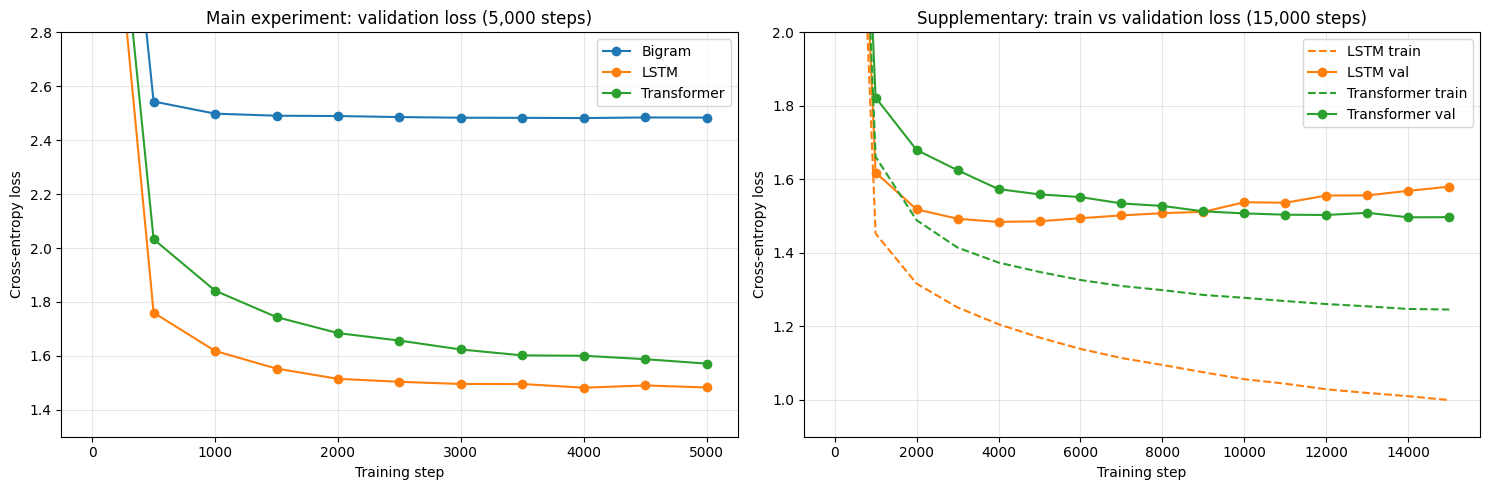

In [28]:
import matplotlib.pyplot as plt

colors = {'Bigram': 'tab:blue', 'LSTM': 'tab:orange', 'Transformer': 'tab:green'}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: main experiment, validation loss for all three models
for name in ['Bigram', 'LSTM', 'Transformer']:
    h = results[name]['history']
    axes[0].plot(h['step'], h['val'], marker='o', color=colors[name], label=name)
axes[0].set_title('Main experiment: validation loss (5,000 steps)')
axes[0].set_xlabel('Training step')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].set_ylim(1.3, 2.8)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: supplementary experiment, train vs val for LSTM and Transformer
for name, base in [('LSTM (15k steps)', 'LSTM'), ('Transformer (15k steps)', 'Transformer')]:
    h = results[name]['history']
    axes[1].plot(h['step'], h['train'], linestyle='--', color=colors[base], label=f'{base} train')
    axes[1].plot(h['step'], h['val'], marker='o', color=colors[base], label=f'{base} val')
axes[1].set_title('Supplementary: train vs validation loss (15,000 steps)')
axes[1].set_xlabel('Training step')
axes[1].set_ylabel('Cross-entropy loss')
axes[1].set_ylim(0.9, 2.0)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('loss_curves.png', dpi=150)
plt.show()

### Loss Curves

The left plot shows the bigram flattening out almost right away around 2.48, while the LSTM and Transformer keep dropping. The LSTM drops faster early on and stays ahead the whole run, but the Transformer's curve is still sloping down at step 5000.

The right plot makes the overfitting story easy to see. For the LSTM, the dashed training line keeps falling toward 1.0 while the solid validation line turns back up after about step 4000, so the two lines drift further and further apart. The Transformer's two lines stay much closer together. The two validation curves meet at around step 9000, and from there on the Transformer stays below the LSTM.

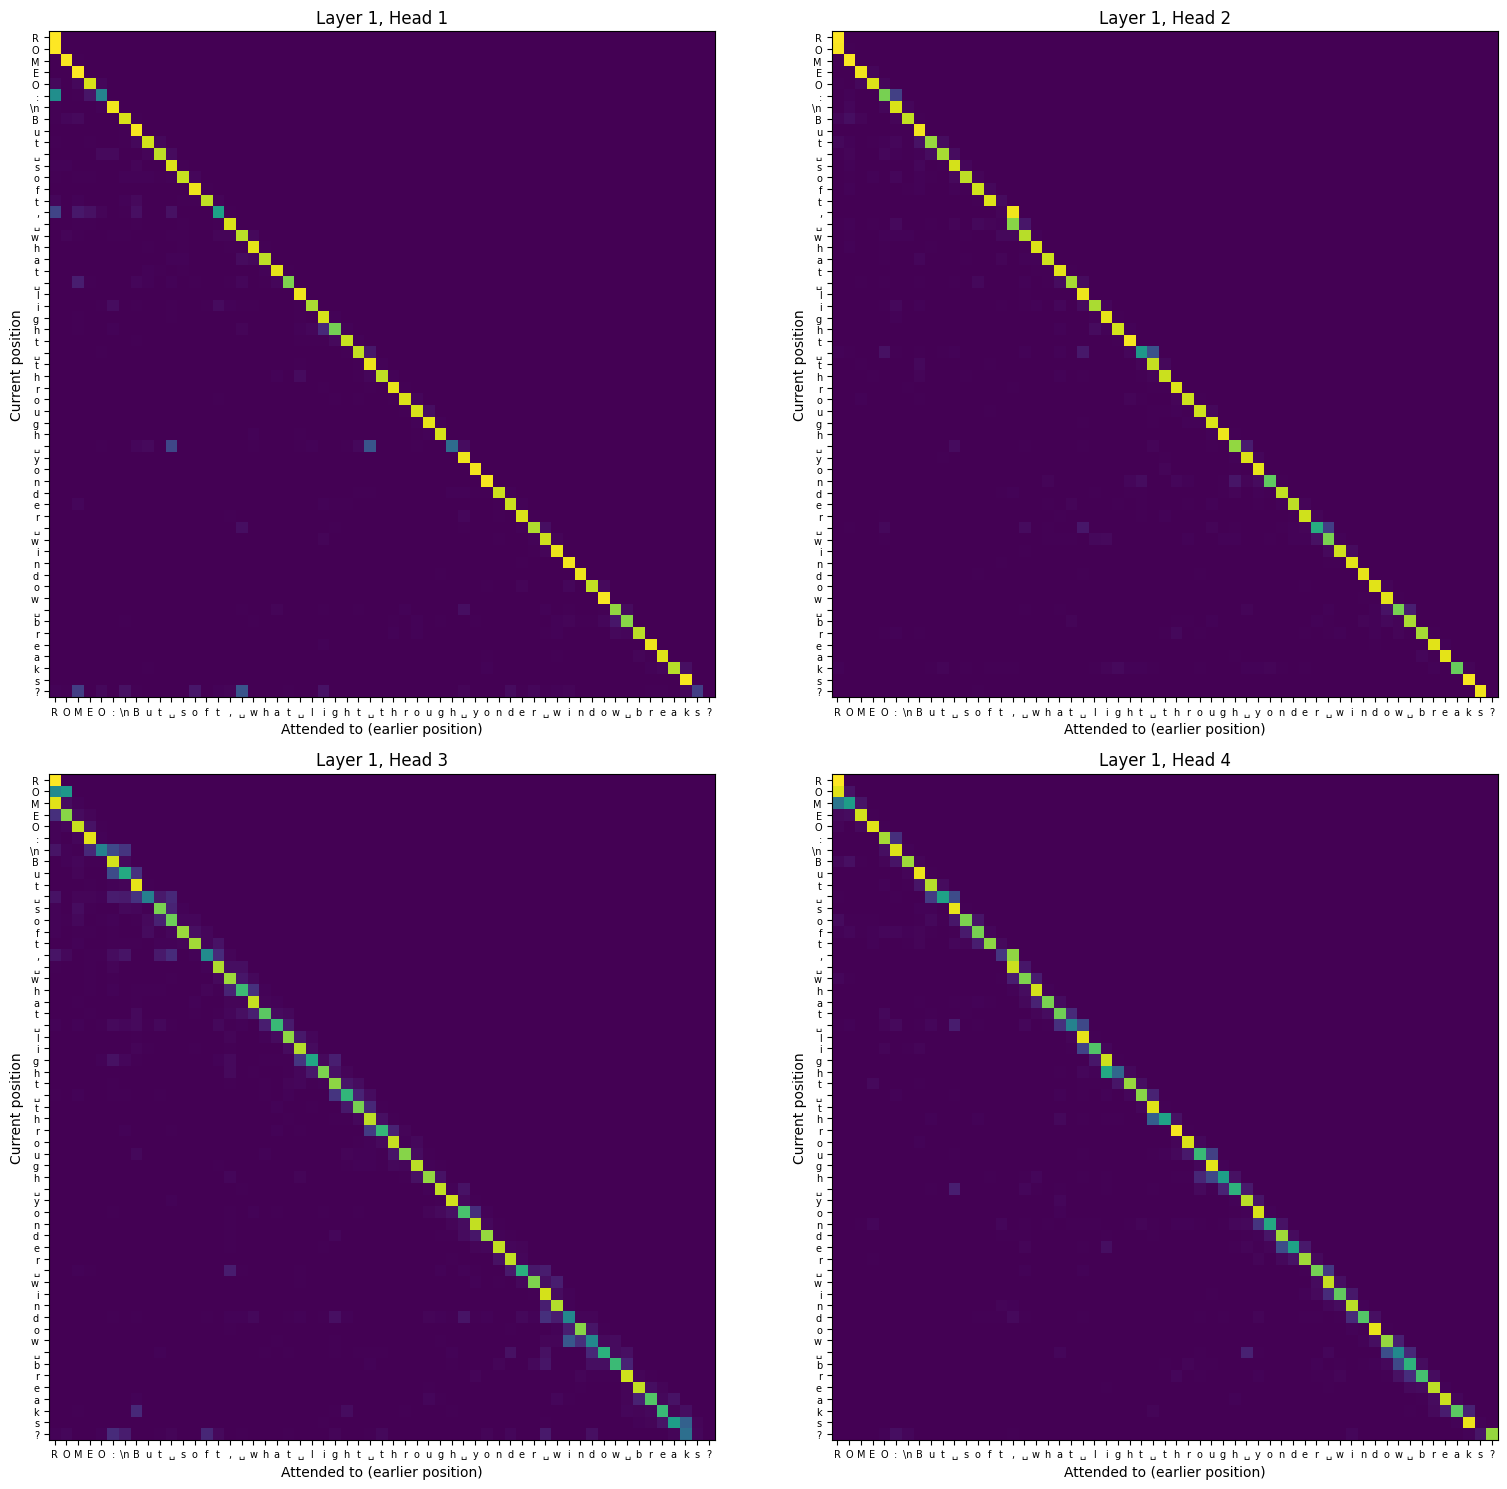

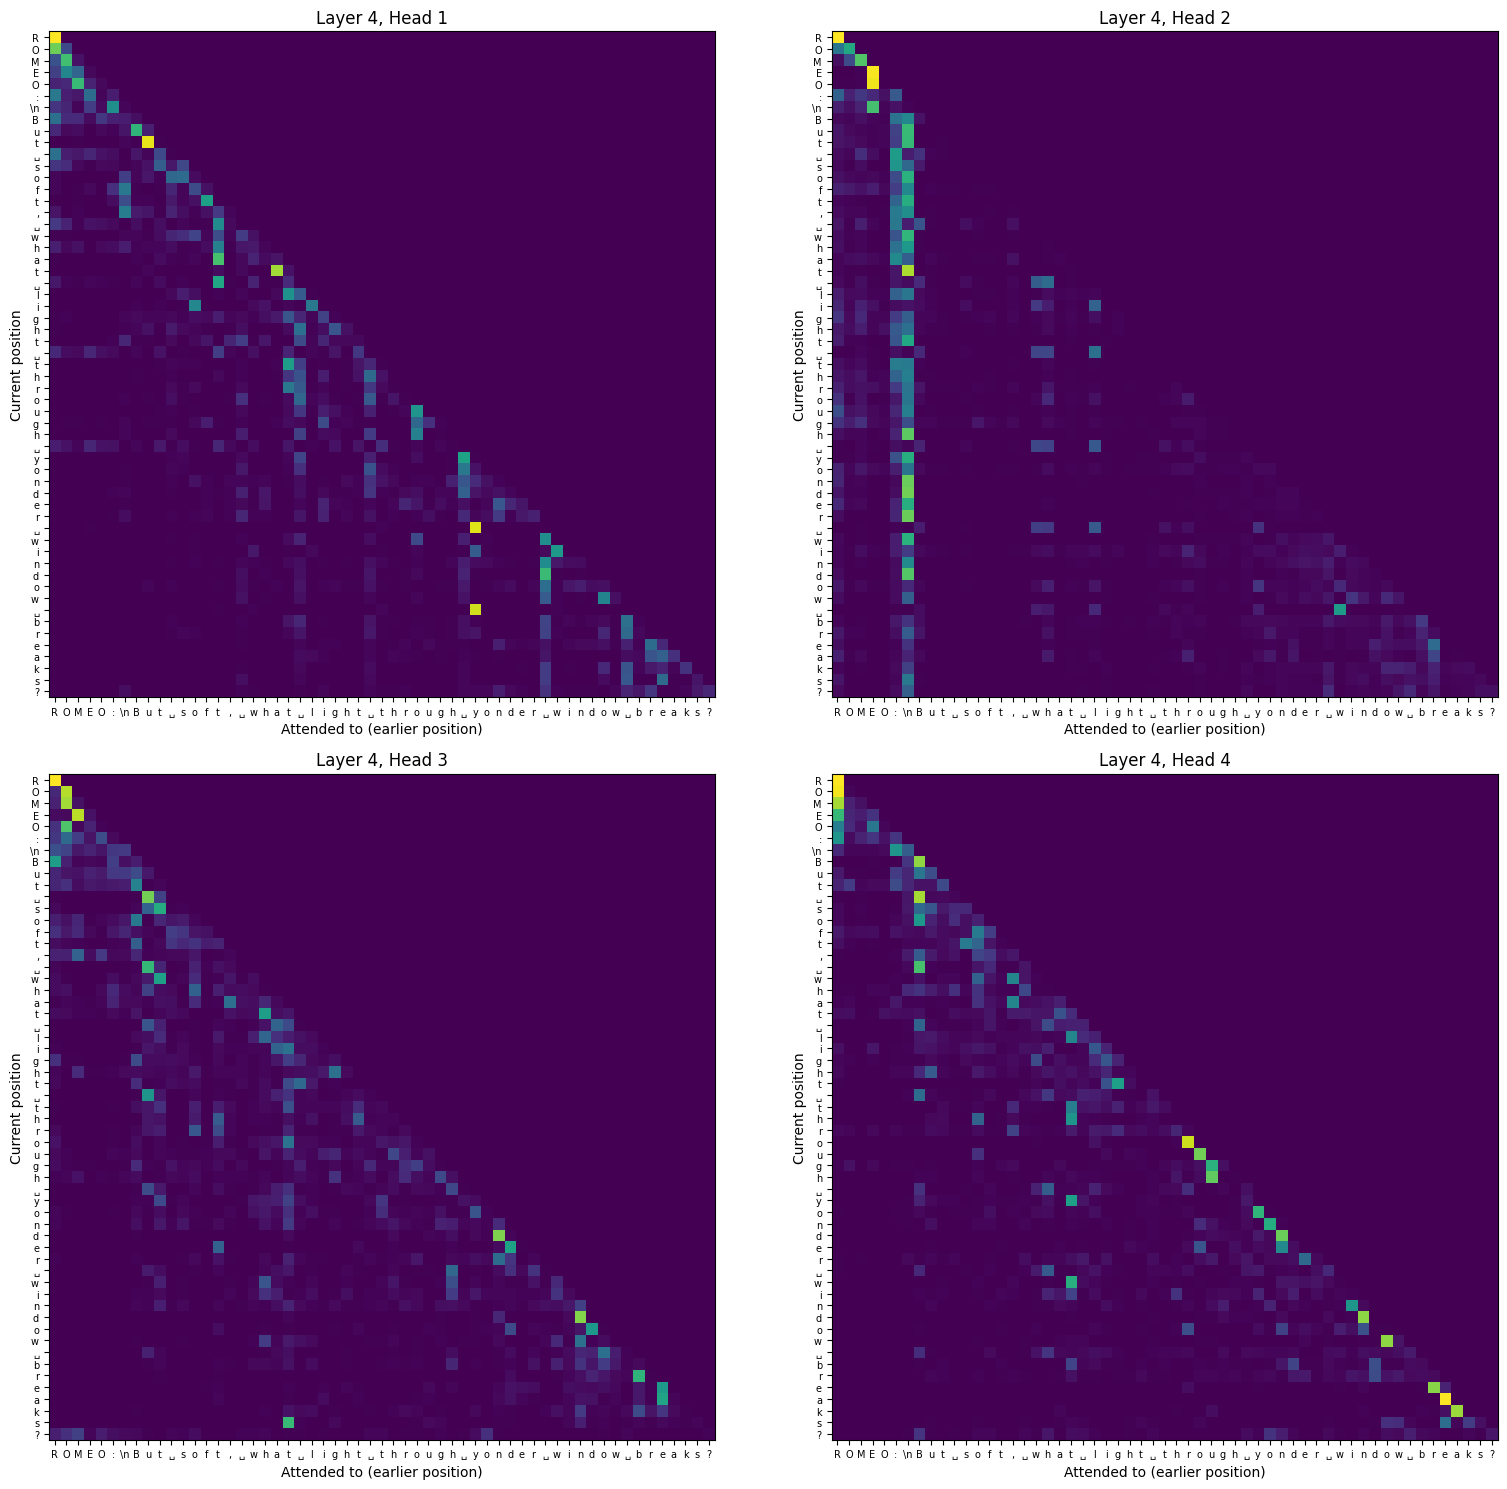

In [29]:
def plot_attention(model, text, layer, filename):
    model.eval()
    idx = torch.tensor([encode(text)], dtype=torch.long, device=device)
    with torch.no_grad():
        model(idx)   # forward pass fills in last_attn for every head
    labels = [c.replace('\n', '\\n').replace(' ', '␣') for c in text]

    heads = model.blocks[layer].sa.heads
    fig, axes = plt.subplots(2, 2, figsize=(16, 15))
    for h, ax in enumerate(axes.flat):
        attn = heads[h].last_attn[0].cpu().numpy()
        ax.imshow(attn, cmap='viridis')
        ax.set_title(f'Layer {layer + 1}, Head {h + 1}')
        ax.set_xticks(range(len(labels)))
        ax.set_yticks(range(len(labels)))
        ax.set_xticklabels(labels, fontsize=7)
        ax.set_yticklabels(labels, fontsize=7)
        ax.set_xlabel('Attended to (earlier position)')
        ax.set_ylabel('Current position')
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

sample_text = "ROMEO:\nBut soft, what light through yonder window breaks?"
plot_attention(transformer_model, sample_text, layer=0, filename='attention_layer1.png')
plot_attention(transformer_model, sample_text, layer=n_layer - 1, filename='attention_layer4.png')

### What the Attention Maps Show

Each heatmap shows, for every character (row), how much attention it pays to each earlier character (column). The upper right triangle is dark in every map because of the causal mask, so no position can peek at the future.

The first layer is pretty simple. All four heads are dominated by a bright diagonal, which means each character mostly attends to itself, and heads 3 and 4 also put some weight on the one or two characters right before it. At this stage the model is mostly working with local spelling, which isn't that different from what the bigram does.

The last layer looks completely different, and each head seems to have its own job. The most striking one is Layer 4, Head 2: nearly every character after the first line puts a lot of attention on the same early spot, the line break (and a bit on the colon) right after "ROMEO:". That's a long range connection the LSTM would have to carry through its hidden state across dozens of steps, but the Transformer can just look it up directly.

At first I wasn't sure what this pattern meant. One possibility is that the head keeps track of where the current speech started. Another is that it's an "attention sink": since softmax forces every row to add up to 1, a head that has nothing useful to look at still has to put its attention somewhere, and models often learn to dump it on one fixed early position. I test this in the next cell.

The other heads in the last layer split up the local work. Head 1 keeps pointing back to spaces and the first letters of earlier words; for example, the spaces before "window" and "breaks" both look hard at the "y" that starts "yonder". Head 4 mostly sticks to the previous character or two inside the current word, which shows up as short bright runs next to the diagonal in words like "through", "yonder", and "window". Head 3 is more spread out and covers the current and previous word.

### Testing the Head 2 Pattern

If Head 2 is tracking the start of the current speech, then giving it a passage with two speakers should make its focus move: once JULIET starts talking, the bright column should jump to the line break after "JULIET:". If it's just an attention sink, the column should stay parked on the first line break no matter what comes after. The model isn't retrained here; I just feed a new piece of text into the same trained Transformer and plot the last layer again.

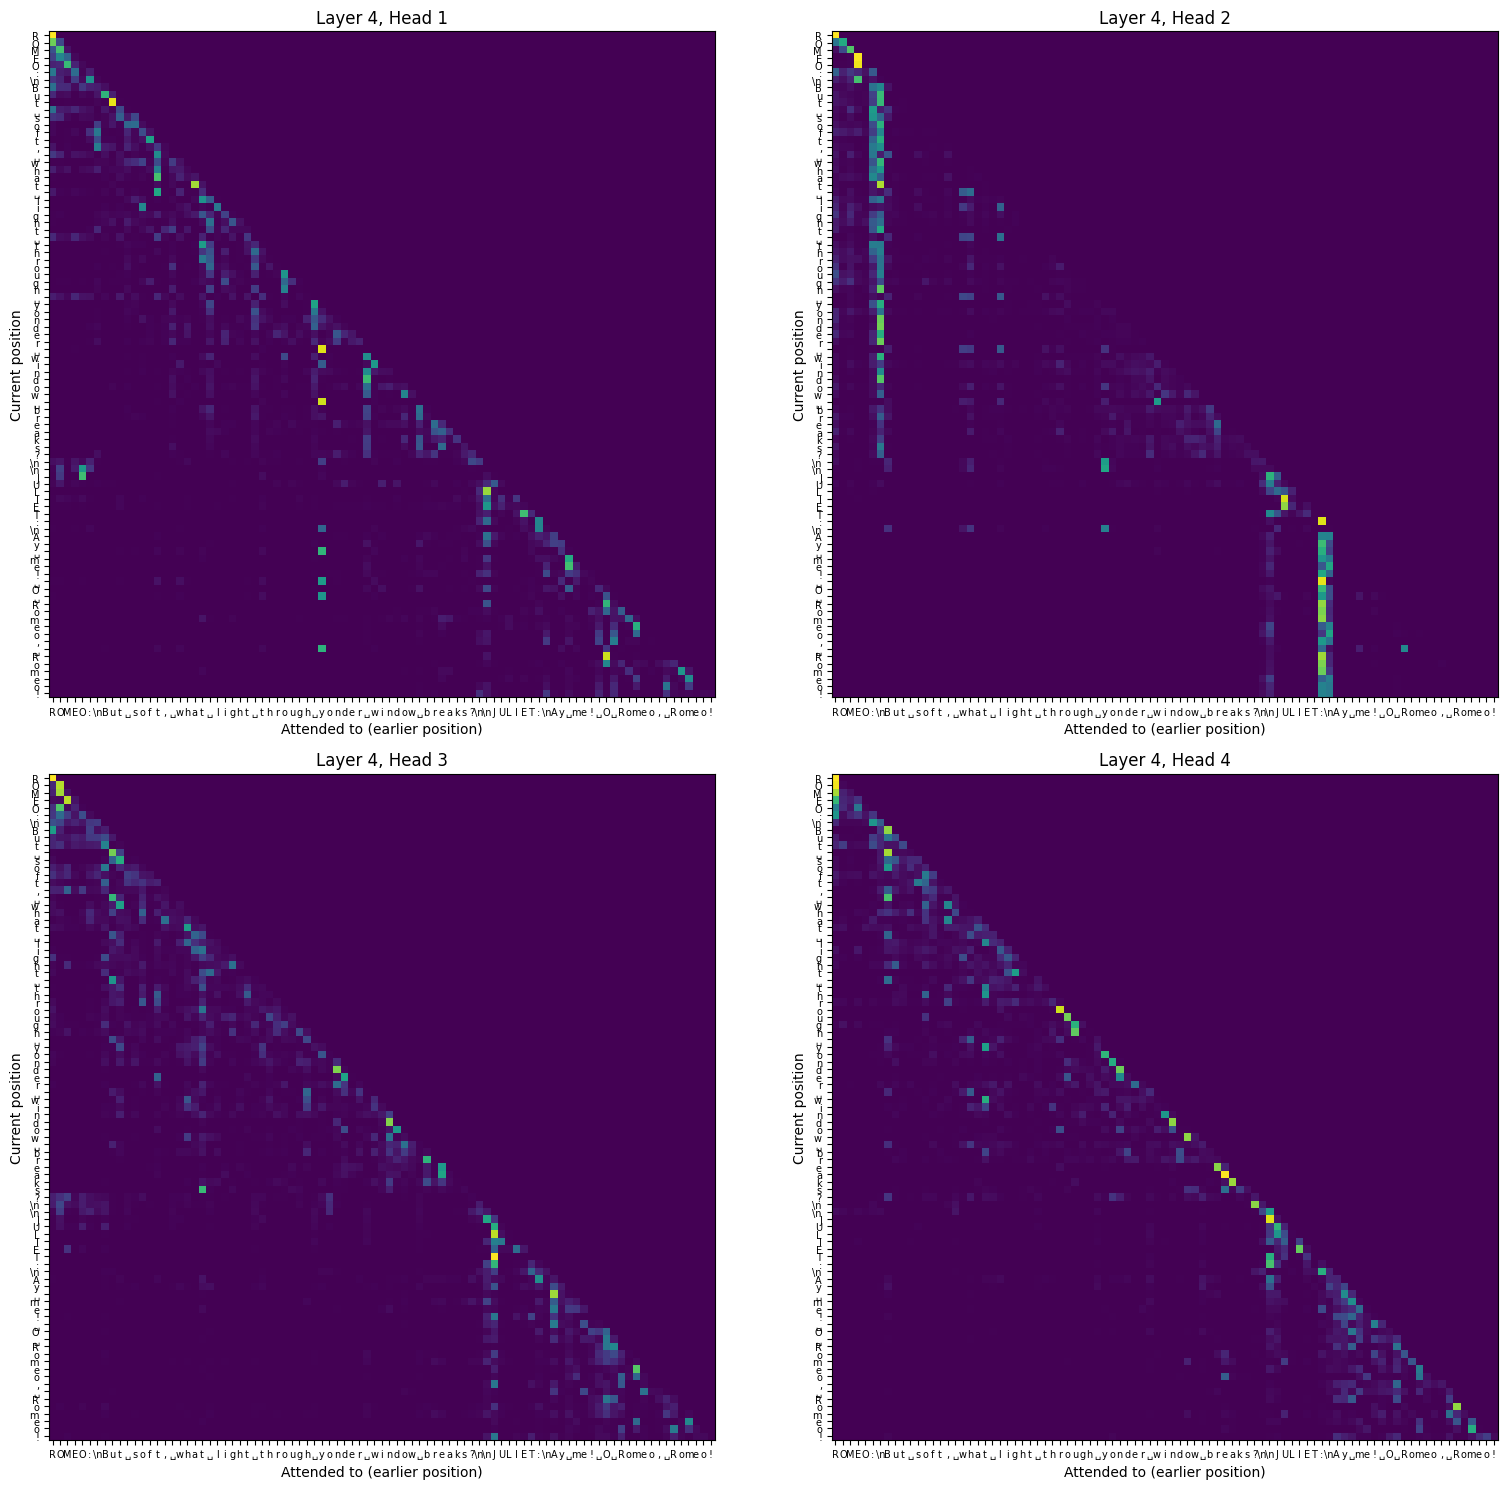

In [31]:
two_speakers = "ROMEO:\nBut soft, what light through yonder window breaks?\n\nJULIET:\nAy me! O Romeo, Romeo!"
plot_attention(transformer_model, two_speakers, layer=n_layer - 1, filename='attention_two_speakers.png')

### What the Test Shows

The result is pretty clear. While Romeo is talking, Head 2 stays locked on the line break after "ROMEO:". But as soon as Juliet starts speaking, the column moves: every character in "Ay me! O Romeo, Romeo!" now points at the line break right after "JULIET:", and the old Romeo column is barely visible anymore. If this were an attention sink, it would stay pinned to the same spot, so this looks much more like the head is tracking where the current speech started. Nobody told the model what a speech is. It figured that out from the data on its own: a speaker name, a colon, and a line break mean a new turn has started, and the most recent one is the one that counts.

The other heads move with the speaker change too. Heads 1, 3, and 4 each find a new reference point around the blank line and the start of "JULIET", so the whole last layer seems to "reset" when the speaker changes. In Head 1, the blank line rows also look back at the letters of "ROMEO", which might be the model getting ready to predict who speaks next. That's just a guess, though, and one example can't prove much.

### What I Learned About Attention

Before this project, attention was basically just a formula to me: softmax(QKᵀ/√d)V. Seeing these maps made it a lot more concrete. The formula only says where a position is allowed to look; where it actually looks is learned from the data. The four heads in a layer have exactly the same structure, but after training they divide up the work on their own: one keeps track of the current speech, while others handle word boundaries and spelling. I used to work in product management, and it reminds me of a team where nobody hands out roles, but after a while everyone finds the job they're best at. The deeper layers also look much further back, so the model builds its understanding one layer at a time, from single characters to words to whole speeches.

It also helped me get the difference between the LSTM and the Transformer. The LSTM has to pass everything forward through one fixed-size hidden state, kind of like a game of telephone, where early details get lost as the message moves from person to person. The Transformer is more like a shared document that everyone can scroll back through. When it wants to know who's speaking, it just goes back and checks the line where the speech started.

One detail from writing the Head class myself really stuck with me. What tripped me up wasn't the three linear layers. It was the question of why the mask uses negative infinity instead of 0. At first I figured filling in 0 would be enough to block those positions, and it took an explanation for me to see why it isn't: softmax takes e^x, and e^0 is still 1, so a 0 doesn't block anything. Only e^(−∞) = 0 actually zeroes the weight out. Once that clicked, the dark upper right triangle in the heatmaps stopped being just "a black area" and became something I could actually read: the weights in those positions are exactly 0.

## 11. Final Reflection

**After comparing bigram, non-transformer, and transformer models, what do you think makes transformers powerful for language modeling?**

Going into this project I assumed the Transformer would just win, and it didn't, at least not right away. With the same 5,000 steps, the LSTM had the lower validation loss and trained faster. That ended up being one of the most useful things I learned, because it made me think harder about where the Transformer's strength actually comes from.

I think the biggest thing is how it handles context. The bigram sees one character. The LSTM can see everything in principle, but it has to cram all of it into one fixed-size hidden state, and older details get squeezed out. The Transformer doesn't have that bottleneck. Every position can look straight back at any earlier position and decide, based on the content, what's worth paying attention to. The Head 2 experiment showed this really clearly: the model learned on its own to look back at the line where the current speech started, and to switch to the new line when the speaker changed. Nobody programmed that in.

The second thing is that attention is split across several heads and stacked into layers. Each head can specialize, so one tracks the speaker while others work on spelling and word boundaries, and the deeper layers combine all of that into a bigger picture. On top of that, a Transformer processes all positions at the same time during training, which is a big reason it scales so well to huge datasets and modern GPUs. In my small setup that advantage was hidden by implementation overhead, but it matters a lot at real scale.

So is the extra complexity worth it? For a 1 MB dataset and a model under a million parameters, honestly not by much, since the LSTM is a tough baseline here. But the longer training run hinted at the bigger picture: the LSTM started overfitting after about 4,000 steps, while the Transformer kept improving (though some of that may come from the extra dropout it gets). My takeaway is that Transformers aren't powerful because they're better at everything. They're powerful because their way of using context keeps paying off as you give them more data, more training, and longer text, which is exactly the direction language models have gone.